In [ ]:
%load_ext autoreload
%autoreload 2
from api import skraafoto
import georeferencing  as geo
import matplotlib.pyplot as plt
from utils import plots, image_handler
import random 

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
stac_item_id = "2023_82_16_2_0004_00003756"
item = skraafoto.fetch_skraafoto_item(stac_item_id)
item

{'type': 'Feature',
 'stac_version': '1.0.0',
 'stac_extensions': ['https://stac-extensions.github.io/view/v1.0.0/schema.json',
  'https://stac-extensions.github.io/projection/v1.0.0/schema.json',
  'https://raw.githubusercontent.com/stac-extensions/perspective-imagery/main/json-schema/schema.json'],
 'id': '2023_82_16_2_0004_00003756',
 'collection': 'skraafotos2023',
 'geometry': {'type': 'Polygon',
  'coordinates': [[[10.029800714452328, 56.443291565649716],
    [10.02735779313822, 56.45315022217864],
    [10.04643090008056, 56.45286511375989],
    [10.043276865340031, 56.44316104991162],
    [10.029800714452328, 56.443291565649716]]]},
 'bbox': [10.02735779313822,
  56.44316104991162,
  10.04643090008056,
  56.45315022217864],
 'properties': {'datetime': '2023-04-01T15:46:59Z',
  'gsd': 0.1,
  'license': 'various',
  'platform': 'Fixed-wing aircraft',
  'instruments': ['UC-OpII-1-70918041-f120_504'],
  'providers': [{'name': 'avt', 'roles': ['producer']},
   {'url': 'https://sdfi.d

In [5]:
image = image_handler.convert_img_to_byte_array(image_handler.extract_selected_image(item))

In [ ]:
tiles_test = geo.split_image_by_latlon(item,image,4,4)
tiles_test

{'2023_82_16_2_0004_00003756': [TileData(tile_image_path='../data/tiles/2023_82_16_2_0004_00003756/tile[10.02735779313822,56.44316104991162,10.032126069873804,56.445658342978376].jpeg', tile_bounds_latlon={'lat_min': np.float64(56.44316104991162), 'lat_max': np.float64(56.445658342978376), 'lon_min': np.float64(10.02735779313822), 'lon_max': np.float64(10.032126069873804)}, pixel_bounds={'x_min': 0, 'x_max': 2031, 'y_min': 0, 'y_max': 2398}, homography=array([[ 6.30327663e-05, -3.85900830e-04,  1.00297968e+01],
         [ 3.47319340e-04, -2.16949189e-03,  5.64433065e+01],
         [ 6.15364831e-06, -3.84527749e-05,  1.00000000e+00]])),
  TileData(tile_image_path='../data/tiles/2023_82_16_2_0004_00003756/tile[10.032126069873804,56.44316104991162,10.03689434660939,56.445658342978376].jpeg', tile_bounds_latlon={'lat_min': np.float64(56.44316104991162), 'lat_max': np.float64(56.445658342978376), 'lon_min': np.float64(10.032126069873804), 'lon_max': np.float64(10.03689434660939)}, pixel_bou

Random Pixel to Convert: (1887, 6628)
Bounding Box in Pixels: x_min=0, x_max=2031, y_min=0, y_max=2398
Checking if (1887, 6628) falls inside...

Bounding Box in Pixels: x_min=1774, x_max=5431, y_min=0, y_max=2474
Checking if (1887, 6628) falls inside...

Bounding Box in Pixels: x_min=5337, x_max=9066, y_min=0, y_max=2492
Checking if (1887, 6628) falls inside...

Bounding Box in Pixels: x_min=8627, x_max=10300, y_min=0, y_max=2492
Checking if (1887, 6628) falls inside...

Bounding Box in Pixels: x_min=0, x_max=2254, y_min=2320, y_max=4396
Checking if (1887, 6628) falls inside...

Bounding Box in Pixels: x_min=2031, x_max=5337, y_min=2398, y_max=4488
Checking if (1887, 6628) falls inside...

Bounding Box in Pixels: x_min=5259, x_max=8627, y_min=2474, y_max=4535
Checking if (1887, 6628) falls inside...

Bounding Box in Pixels: x_min=8259, x_max=10300, y_min=2482, y_max=4593
Checking if (1887, 6628) falls inside...

Bounding Box in Pixels: x_min=0, x_max=2431, y_min=4345, y_max=6145
Checki

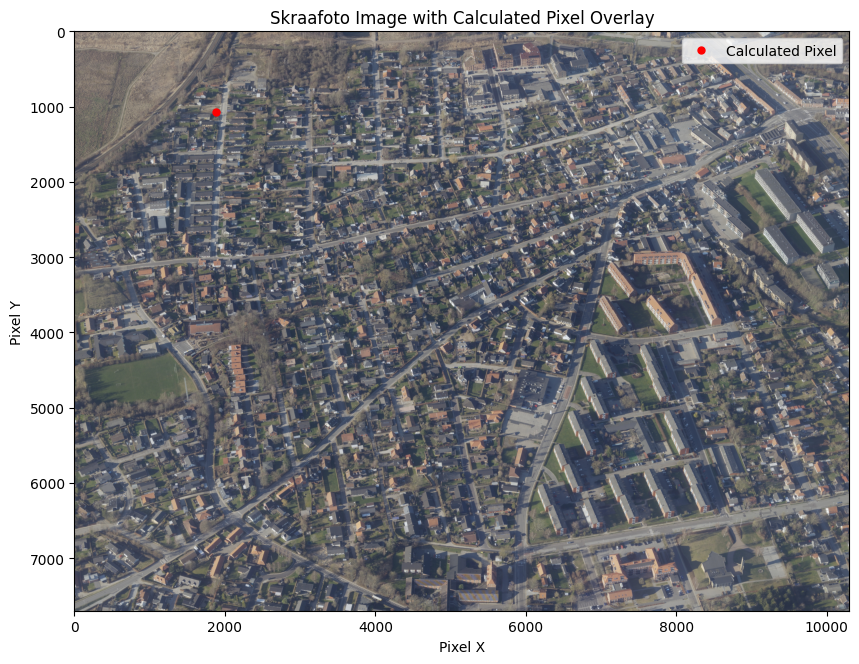

lat: 56.451406403265814
lon10.03108603215342


In [ ]:
random_pixel_x = random.randint(0, image.shape[1] - 1)
random_pixel_y = random.randint(0, image.shape[0] - 1)

print(f"Random Pixel to Convert: {random_pixel_x, random_pixel_y}")

tile = geo.get_tile_for_pixel(random_pixel_x, random_pixel_y, stac_item_id, tiles_test)
projected_points = geo.convert_pixel_to_world_homography(random_pixel_x,random_pixel_y, tile.homography)
print(f"Projected lon lat: {projected_points}")

image = skraafoto.get_image_from_url(image_handler.extract_selected_image(item))

plots.plot_pixel_on_image([random_pixel_x,random_pixel_y],image)

print(f"lat: {projected_points[1]}")
print(f"lon{projected_points[0]}")
plots.generate_map_with_projected_point(projected_points[1], projected_points[0],item['bbox'], f'test_pixels:{random_pixel_x, random_pixel_y}')

Processing tile:  0
Generating lat long within bbx: (np.float64(56.44316104991162), np.float64(10.02735779313822), np.float64(56.445658342978376), np.float64(10.032126069873804))
Processing tile:  1
Generating lat long within bbx: (np.float64(56.44316104991162), np.float64(10.032126069873804), np.float64(56.445658342978376), np.float64(10.03689434660939))
Processing tile:  2
Generating lat long within bbx: (np.float64(56.44316104991162), np.float64(10.03689434660939), np.float64(56.445658342978376), np.float64(10.041662623344976))
Processing tile:  3
Generating lat long within bbx: (np.float64(56.44316104991162), np.float64(10.041662623344976), np.float64(56.445658342978376), np.float64(10.04643090008056))
Processing tile:  4
Generating lat long within bbx: (np.float64(56.445658342978376), np.float64(10.02735779313822), np.float64(56.44815563604513), np.float64(10.032126069873804))
Processing tile:  5
Generating lat long within bbx: (np.float64(56.445658342978376), np.float64(10.032126

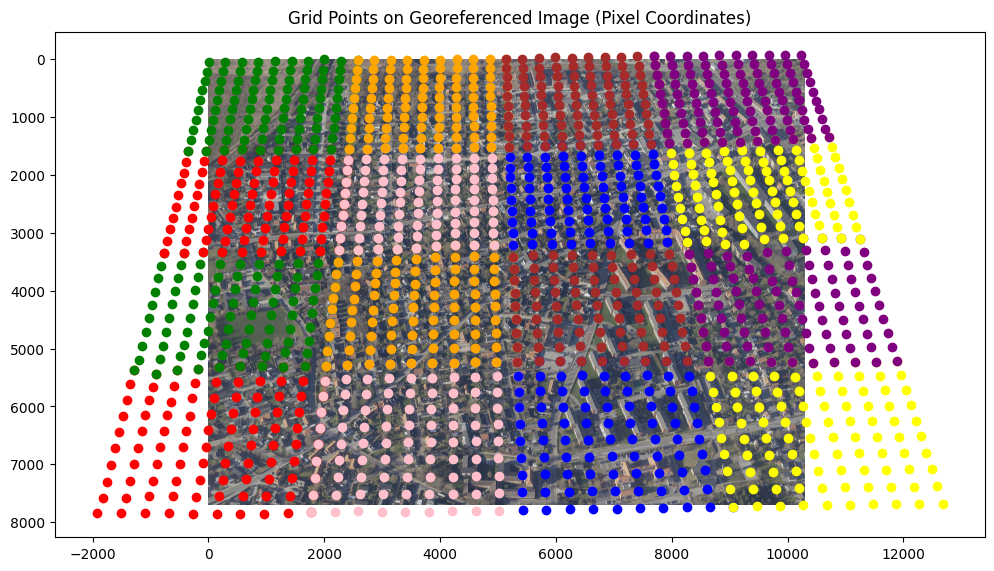

In [ ]:
# tiles: list[tile_model.TileData]= image_tiling.split_image_by_latlon(item,4,4)
index = 0;
colors = ['red','pink', 'blue', 'yellow','green','orange','brown','purple','red','pink', 'blue', 'yellow','green','orange','brown','purple']
fig, ax = plt.subplots(figsize=(12, 12))
ax.imshow(image)

for id, tile_list in tiles_test.items(): 
    for tile in tile_list: 
        print(f"Processing tile:  {index}")
        tile_bound_latlon = tile.tile_bounds_latlon
        lon_min = tile_bound_latlon['lon_min']
        lon_max = tile_bound_latlon['lon_max']
        lat_min = tile_bound_latlon['lat_min']
        lat_max = tile_bound_latlon['lat_max']
        print (f"Generating lat long within bbx: {lat_min,lon_min,lat_max,lon_max}")
        grid = geo.generate_real_world_points(lon_min,lat_min,lon_max, lat_max)
        lats = grid[:, 1]
        lons = grid[:, 0]
        pixel_coords = [geo.latlon_to_pixel(lat, lon, item) for lat, lon in zip(lats, lons)]
        pixels_x = [pt[0] for pt in pixel_coords]
        pixels_y = [pt[1] for pt in pixel_coords]
        inverted_ys = [image.shape[0] - y for y in pixels_y ]
        color = colors[index]
        ax.scatter(pixels_x, inverted_ys, c=color, marker='o')
        index +=1


ax.set_title('Grid Points on Georeferenced Image (Pixel Coordinates)')

plt.show()   

In [ ]:
tiles_test = geo.split_image_by_latlon(item,image,4,4)
tiles_test

{'2023_82_16_2_0004_00003756': [TileData(tile_image_path='../data/tiles/2023_82_16_2_0004_00003756/tile[10.02735779313822,56.44316104991162,10.032126069873804,56.445658342978376].jpeg', tile_bounds_latlon={'lat_min': np.float64(56.44316104991162), 'lat_max': np.float64(56.445658342978376), 'lon_min': np.float64(10.02735779313822), 'lon_max': np.float64(10.032126069873804)}, pixel_bounds={'x_min': 0, 'x_max': 2031, 'y_min': 0, 'y_max': 2398}, homography=array([[ 6.30327663e-05, -3.85900830e-04,  1.00297968e+01],
         [ 3.47319340e-04, -2.16949189e-03,  5.64433065e+01],
         [ 6.15364831e-06, -3.84527749e-05,  1.00000000e+00]])),
  TileData(tile_image_path='../data/tiles/2023_82_16_2_0004_00003756/tile[10.032126069873804,56.44316104991162,10.03689434660939,56.445658342978376].jpeg', tile_bounds_latlon={'lat_min': np.float64(56.44316104991162), 'lat_max': np.float64(56.445658342978376), 'lon_min': np.float64(10.032126069873804), 'lon_max': np.float64(10.03689434660939)}, pixel_bou